Nama: Dian Rohmatul Islam

Nim: 24031554047

Mata Kuliah: Graf Sains Data

Kelas: 2024B

### Import Library

In [135]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

from neo4j import GraphDatabase
from scipy.sparse import csr_matrix
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import normalize

Mengimpor library yang diperlukan;
1. os untuk pengelolaan path dan file
2. pandas dan numpy untuk pengolahan data
3. matplotlib.pyplot dan networkx untuk visualisasi data dan graf
4. GraphDatabase untuk mengakses Neo4j
5. csr_matrix untuk merepresentasikan matriks sparse
6. cosine_similarity untuk menghitung kemiripan antarvektor
7. normalize untuk normalisasi matriks

### Baca dataset

In [2]:
DATA_DIR = "Dataset"
print(os.getcwd())

print("\nDaftar file:")
for nama_file in sorted(os.listdir(DATA_DIR)):
    print(nama_file)


c:\Users\ASUS\OneDrive\Documents\Semester 5\Graf Sains Data\047_DIAN R.I_UTS Graf Sains Data

Daftar file:
category_tree.csv
events.csv
item_properties_part1.csv
item_properties_part2.csv


1. Baca dataset events

In [3]:
df_events = pd.read_csv(
    os.path.join(DATA_DIR, "events.csv")
)

df_events

,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN
...,...,...,...,...,...
2756096,1438398785939,591435,view,261427,NaN
2756097,1438399813142,762376,view,115946,NaN
2756098,1438397820527,1251746,view,78144,NaN
2756099,1438398530703,1184451,view,283392,NaN


 2. Baca dataset category tree

In [4]:
df_category_tree = pd.read_csv(
    os.path.join(DATA_DIR, "category_tree.csv")
)

df_category_tree

,categoryid,parentid
0,1016,213.0
1,809,169.0
2,570,9.0
3,1691,885.0
4,536,1691.0
...,...,...
1664,49,1125.0
1665,1112,630.0
1666,1336,745.0
1667,689,207.0


3. Baca dataset item properties part 1

In [5]:
df_properties_1 = pd.read_csv(
    os.path.join(DATA_DIR, "item_properties_part1.csv")
)

df_properties_1

,timestamp,itemid,property,value
0,1435460400000,460429,categoryid,1338
1,1441508400000,206783,888,1116713 960601 n277.200
2,1439089200000,395014,400,n552.000 639502 n720.000 424566
3,1431226800000,59481,790,n15360.000
4,1431831600000,156781,917,828513
...,...,...,...,...
10999994,1439694000000,86599,categoryid,618
10999995,1435460400000,153032,1066,n1020.000 424566
10999996,1440298800000,421788,888,35975 856003 37346
10999997,1437879600000,159792,400,n552.000 639502 n720.000 424566


4. Baca dataset item properties part 2

In [6]:
df_properties_2 = pd.read_csv(
    os.path.join(DATA_DIR, "item_properties_part2.csv")
)

df_properties_2

,timestamp,itemid,property,value
0,1433041200000,183478,561,769062
1,1439694000000,132256,976,n26.400 1135780
2,1435460400000,420307,921,1149317 1257525
3,1431831600000,403324,917,1204143
4,1435460400000,230701,521,769062
...,...,...,...,...
9275898,1433646000000,236931,929,n12.000
9275899,1440903600000,455746,6,150169 639134
9275900,1439694000000,347565,686,610834
9275901,1433646000000,287231,867,769062


Dataset RetailRocket dibaca untuk memperoleh data interaksi pengunjung, struktur kategori, dan properti item. Data ini digunakan sebagai dasar analisis interaksi user-item dan pembangunan graph pada Neo4j.

# 2.1 Wrangling dan EDA — Progres

### Exploratory Data Analysis (EDA) 

1. Informasi Dataset events

In [7]:
df_events.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2756101 entries, 0 to 2756100
Data columns (total 5 columns):
 #   Column         Dtype  
---  ------         -----  
 0   timestamp      int64  
 1   visitorid      int64  
 2   event          object 
 3   itemid         int64  
 4   transactionid  float64
dtypes: float64(1), int64(3), object(1)
memory usage: 105.1+ MB


cek jumlah baris, kolom, tipe data, dan keberadaan nilai kosong

2. Statistik deskriptif

In [8]:
df_events.describe(include="all")

,timestamp,visitorid,event,itemid,transactionid
count,2.756101e+06,2.756101e+06,2756101,2.756101e+06,22457.000000
unique,NaN,NaN,3,NaN,NaN
top,NaN,NaN,view,NaN,NaN
freq,NaN,NaN,2664312,NaN,NaN
mean,1.436424e+12,7.019229e+05,NaN,2.349225e+05,8826.497796
std,3.366312e+09,4.056875e+05,NaN,1.341954e+05,5098.996290
min,1.430622e+12,0.000000e+00,NaN,3.000000e+00,0.000000
25%,1.433478e+12,3.505660e+05,NaN,1.181200e+05,4411.000000
50%,1.436453e+12,7.020600e+05,NaN,2.360670e+05,8813.000000
75%,1.439225e+12,1.053437e+06,NaN,3.507150e+05,13224.000000


3. Distribusi event

In [9]:
df_events["event"].value_counts()

event
view           2664312
addtocart        69332
transaction      22457
Name: count, dtype: int64

4. Persentase event

In [10]:
(df_events["event"].value_counts(normalize=True) * 100).round(2)

event
view           96.67
addtocart       2.52
transaction     0.81
Name: proportion, dtype: float64

5. Rentang waktu dataset

In [11]:
df_events["datetime"] = pd.to_datetime(
    df_events["timestamp"],
    unit="ms"
)

df_events["datetime"].agg(["min", "max"])

min   2015-05-03 03:00:04.384
max   2015-09-18 02:59:47.788
Name: datetime, dtype: datetime64[ns]

Statistik deskriptif dan distribusi event untuk memahami pola interaksi pengunjung. Event terdiri atas `view`, `addtocart`, dan `transaction`. Rentang waktu diperiksa untuk menentukan periode training dan testing yang sesuai.

### Data Wrangling

1. Konversi Timestamp ke Datetime

In [12]:
df_events["datetime"] = pd.to_datetime(
    df_events["timestamp"],
    unit="ms"
)

df_events[["timestamp", "datetime", "event"]]

,timestamp,datetime,event
0,1433221332117,2015-06-02 05:02:12.117,view
1,1433224214164,2015-06-02 05:50:14.164,view
2,1433221999827,2015-06-02 05:13:19.827,view
3,1433221955914,2015-06-02 05:12:35.914,view
4,1433221337106,2015-06-02 05:02:17.106,view
...,...,...,...
2756096,1438398785939,2015-08-01 03:13:05.939,view
2756097,1438399813142,2015-08-01 03:30:13.142,view
2756098,1438397820527,2015-08-01 02:57:00.527,view
2756099,1438398530703,2015-08-01 03:08:50.703,view


Timestamp Unix dikonversi menjadi format datetime agar waktu interaksi dapat dibaca dan difilter berdasarkan periode yang ditentukan

### Nomor 1 — Menentukan periode P1 dan P2

2. Penentuan Periode dan Filtering Data Training–Testing

In [13]:
start_p1 = "2015-05-03"
end_p1 = "2015-05-18"

start_p2 = "2015-05-18"
end_p2 = "2015-06-01"

# Filter data training (P1)
df_p1 = df_events[
    (df_events["datetime"] >= start_p1) &
    (df_events["datetime"] < end_p1)
].copy()

# Filter data testing (P2)
df_p2 = df_events[
    (df_events["datetime"] >= start_p2) &
    (df_events["datetime"] < end_p2)
].copy()

3. Validasi Hasil Filter

In [14]:
pd.DataFrame({
    "Periode": ["P1 - Training", "P2 - Testing"],
    "Jumlah Interaksi": [
        len(df_p1),
        len(df_p2)
    ],
    "Tanggal Awal": [
        df_p1["datetime"].min(),
        df_p2["datetime"].min()
    ],
    "Tanggal Akhir": [
        df_p1["datetime"].max(),
        df_p2["datetime"].max()
    ]
})

,Periode,Jumlah Interaksi,Tanggal Awal,Tanggal Akhir
0,P1 - Training,296319,2015-05-03 03:00:04.384,2015-05-17 23:59:55.746
1,P2 - Testing,294333,2015-05-18 00:00:01.025,2015-05-31 23:59:59.911


Data dibagi menjadi dua periode, yaitu P1 sebagai data training dan P2 sebagai data testing. Pembagian waktu ini digunakan untuk membangun model dari interaksi terdahulu dan mengevaluasi rekomendasi menggunakan interaksi pada periode berikutnya. Hasil filter divalidasi untuk memastikan periode sesuai dengan ketentuan yang digunakan.

### Nomor 2 — Filter timestamp dan menyimpan CSV

In [15]:
os.makedirs("Hasil", exist_ok=True)

df_p1.to_csv("Hasil/events_training.csv", index=False)
df_p2.to_csv("Hasil/events_testing.csv", index=False)

os.listdir("Hasil")

['events_testing.csv', 'events_training.csv']

In [16]:
df_p1 #Data Training

,timestamp,visitorid,event,itemid,transactionid,datetime
1462519,1430631920036,241793,view,287090,NaN,2015-05-03 05:45:20.036
1462520,1430630651248,1206788,view,116444,NaN,2015-05-03 05:24:11.248
1462521,1430630817282,624610,view,362372,NaN,2015-05-03 05:26:57.282
1462522,1430630450987,1407102,view,454806,NaN,2015-05-03 05:20:50.987
1462523,1430630220903,283409,view,262826,NaN,2015-05-03 05:17:00.903
...,...,...,...,...,...,...
1767411,1431895205133,135074,view,206528,NaN,2015-05-17 20:40:05.133
1767412,1431895205102,1346082,view,193182,NaN,2015-05-17 20:40:05.102
1767413,1431896186284,575293,view,170044,NaN,2015-05-17 20:56:26.284
1767414,1431895977363,1125737,view,405934,NaN,2015-05-17 20:52:57.363


In [17]:
df_p2 #Data Testing

,timestamp,visitorid,event,itemid,transactionid,datetime
1744909,1431919909899,888972,view,208003,NaN,2015-05-18 03:31:49.899
1744910,1431919097699,320036,view,397277,NaN,2015-05-18 03:18:17.699
1744911,1431921466093,1141758,view,115643,NaN,2015-05-18 03:57:46.093
1744912,1431918065764,807187,view,203658,NaN,2015-05-18 03:01:05.764
1744913,1431920893470,1088018,view,216474,NaN,2015-05-18 03:48:13.470
...,...,...,...,...,...,...
2058975,1433108448794,171927,view,94756,NaN,2015-05-31 21:40:48.794
2058976,1433104537672,1340945,view,39856,NaN,2015-05-31 20:35:37.672
2058977,1433109373647,1347613,view,149505,NaN,2015-05-31 21:56:13.647
2058978,1433105065368,1133403,view,157457,NaN,2015-05-31 20:44:25.368


Data interaksi yang telah difilter disimpan ke dalam file CSV terpisah untuk training dan testing agar menjaga konsistensi data pada tahap pemodelan dan evaluasi.

### Koneksi Python ke Neo4j Dekstop

1. Siapkan koneksi Python

In [ ]:
NEO4J_URI = "neo4j://127.0.0.1:7687"
NEO4J_USERNAME = "neo4j"
NEO4J_PASSWORD = input("Masukkan password Neo4j lokal: ")

driver = GraphDatabase.driver(
    NEO4J_URI,
    auth=(NEO4J_USERNAME, NEO4J_PASSWORD)
)

driver.verify_connectivity()

print("Koneksi ke Neo4j lokal berhasil!")

Koneksi ke Neo4j lokal berhasil!


2. Periksa database lokal

In [19]:
with driver.session(database="retailrocket") as session:
    result = session.run("""
        MATCH (n)
        RETURN count(n) AS total_node
    """)
    print(result.single()["total_node"])

234087


3. Memastikan file CSV

In [ ]:
csv_path = "Hasil/events_training.csv"

print("File ditemukan:", os.path.exists(csv_path))

if os.path.exists(csv_path):
    print("Lokasi file:", os.path.abspath(csv_path))

File ditemukan: True
Lokasi file: c:\Users\ASUS\OneDrive\Documents\Semester 5\Graf Sains Data\047_DIAN R.I_UTS Graf Sains Data\Hasil\events_training.csv


In [ ]:
csv_path = r"Hasil/events_training.csv"
df_train = pd.read_csv(csv_path)

print("Jumlah baris:", len(df_train))
print("Nama kolom:", df_train.columns.tolist())
print("\nJumlah event:")
print(df_train["event"].value_counts())

display(df_train.head())

Jumlah baris: 296319
Nama kolom: ['timestamp', 'visitorid', 'event', 'itemid', 'transactionid', 'datetime']

Jumlah event:
event
view           286485
addtocart        7430
transaction      2404
Name: count, dtype: int64


,timestamp,visitorid,event,itemid,transactionid,datetime
0,1430631920036,241793,view,287090,NaN,2015-05-03 05:45:20.036
1,1430630651248,1206788,view,116444,NaN,2015-05-03 05:24:11.248
2,1430630817282,624610,view,362372,NaN,2015-05-03 05:26:57.282
3,1430630450987,1407102,view,454806,NaN,2015-05-03 05:20:50.987
4,1430630220903,283409,view,262826,NaN,2015-05-03 05:17:00.903


4. Buat struktur graph dan impor data

In [ ]:
csv_path = r"Hasil/events_training.csv"
df_train = pd.read_csv(csv_path)

# Bersihkan data yang tidak memiliki ID atau timestamp
df_train = df_train.dropna(
    subset=["visitorid", "itemid", "timestamp", "event"]
).copy()

df_train["visitorid"] = df_train["visitorid"].astype("int64")
df_train["itemid"] = df_train["itemid"].astype("int64")
df_train["timestamp"] = df_train["timestamp"].astype("int64")
df_train["event"] = df_train["event"].str.lower().str.strip()

df_train = df_train[
    df_train["event"].isin(["view", "addtocart", "transaction"])
].copy()

batch_size = 5000

with driver.session(database="retailrocket") as session:

    # 1. Constraint ID unik
    session.run("""
        CREATE CONSTRAINT visitor_id_unique IF NOT EXISTS
        FOR (v:Visitor) REQUIRE v.visitorid IS UNIQUE
    """).consume()

    session.run("""
        CREATE CONSTRAINT item_id_unique IF NOT EXISTS
        FOR (i:Item) REQUIRE i.itemid IS UNIQUE
    """).consume()

    # 2. Buat node Visitor dan Item
    visitor_rows = [
        {"visitorid": int(x)}
        for x in df_train["visitorid"].unique()
    ]
    item_rows = [
        {"itemid": int(x)}
        for x in df_train["itemid"].unique()
    ]

    for start in range(0, len(visitor_rows), batch_size):
        session.run("""
            UNWIND $rows AS row
            MERGE (:Visitor {visitorid: row.visitorid})
        """, rows=visitor_rows[start:start + batch_size]).consume()

    for start in range(0, len(item_rows), batch_size):
        session.run("""
            UNWIND $rows AS row
            MERGE (:Item {itemid: row.itemid})
        """, rows=item_rows[start:start + batch_size]).consume()

    print("Node Visitor:", len(visitor_rows))
    print("Node Item:", len(item_rows))

    # 3. Impor relasi interaksi
    query_event = {
        "view": """
            UNWIND $rows AS row
            MATCH (v:Visitor {visitorid: row.visitorid})
            MATCH (i:Item {itemid: row.itemid})
            MERGE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)
        """,
        "addtocart": """
            UNWIND $rows AS row
            MATCH (v:Visitor {visitorid: row.visitorid})
            MATCH (i:Item {itemid: row.itemid})
            MERGE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)
        """,
        "transaction": """
            UNWIND $rows AS row
            MATCH (v:Visitor {visitorid: row.visitorid})
            MATCH (i:Item {itemid: row.itemid})
            MERGE (v)-[r:BOUGHT {timestamp: row.timestamp}]->(i)
            SET r.transactionId = row.transactionid
        """
    }

    for event_name, query in query_event.items():
        df_event = df_train[df_train["event"] == event_name]
        total = 0

        for start in range(0, len(df_event), batch_size):
            batch = df_event.iloc[start:start + batch_size]

            rows = []
            for r in batch.itertuples(index=False):
                transactionid = getattr(r, "transactionid", None)

                if pd.isna(transactionid):
                    transactionid = None
                else:
                    transactionid = int(transactionid)

                rows.append({
                    "visitorid": int(r.visitorid),
                    "itemid": int(r.itemid),
                    "timestamp": int(r.timestamp),
                    "transactionid": transactionid
                })

            if rows:
                session.run(
                    query, rows=rows
                ).consume()
                total += len(rows)

        print(f"{event_name}: {total:,} baris diproses")

print("Pembuatan struktur graph dan impor data selesai.")


Node Visitor: 155916
Node Item: 78171
view: 286,485 baris diproses
addtocart: 7,430 baris diproses
transaction: 2,404 baris diproses
Pembuatan struktur graph dan impor data selesai.


Python dihubungkan ke database Neo4j lokal untuk membangun graph dari data training. Node merepresentasikan pengunjung (`Visitor`) dan item (`Item`), sedangkan relasi merepresentasikan interaksi `VIEWED`, `ADDED_TO_CART`, dan `BOUGHT` sesuai jenis event.

### Nomor 3 — Komposisi subgraph

1. Verifikasi graph

In [23]:
with driver.session(database="retailrocket") as session:
    print("=== JUMLAH NODE ===")
    result = session.run("""
        MATCH (n)
        RETURN labels(n) AS tipe_node, count(*) AS jumlah
        ORDER BY tipe_node
    """)

    for record in result:
        print(record["tipe_node"], record["jumlah"])

    print("\n=== JUMLAH RELASI ===")
    result = session.run("""
        MATCH ()-[r]->()
        RETURN type(r) AS tipe_relasi, count(*) AS jumlah
        ORDER BY tipe_relasi
    """)

    for record in result:
        print(record["tipe_relasi"], record["jumlah"])

=== JUMLAH NODE ===
['Item'] 78171
['Visitor'] 155916

=== JUMLAH RELASI ===
ADDED_TO_CART 7430
BOUGHT 2404
SIMILAR_TO 5
VIEWED 286485


Berdasarkan hasil verifikasi graph menggunakan Neo4j, struktur graph pada dataset RetailRocket terdiri atas beberapa jenis simpul (*node*) dan relasi (*relationship*). Simpul merepresentasikan entitas dalam dataset, sedangkan relasi menggambarkan hubungan atau interaksi antarentitas.

**1. Interpretasi Simpul (*Node*)**

Jumlah simpul dihitung berdasarkan label menggunakan query Cypher `MATCH (n)` dan `labels(n)`. Pada graph ini, terdapat dua jenis simpul utama, yaitu:

- **Visitor**: merepresentasikan pengunjung atau pengguna yang melakukan interaksi dengan produk.
- **Item**: merepresentasikan produk yang menjadi objek interaksi pengunjung.

Jumlah masing-masing simpul menunjukkan banyaknya pengunjung unik dan produk unik yang tersimpan dalam graph.

**2. Interpretasi Relasi (*Relationship*)**

Relasi dihitung menggunakan query Cypher `MATCH ()-[r]->()` dan `type(r)`. Terdapat tiga jenis relasi interaksi utama:

- **VIEWED**: menunjukkan bahwa pengunjung melihat suatu produk.
- **ADDED_TO_CART**: menunjukkan bahwa pengunjung menambahkan produk ke keranjang.
- **BOUGHT**: menunjukkan bahwa pengunjung melakukan transaksi pembelian produk.

Jumlah setiap relasi menunjukkan banyaknya hubungan interaksi yang tersimpan pada graph sesuai dengan tipe relasinya.


### VSM

In [24]:
with driver.session(database="retailrocket") as session:
    result = session.run("""
        MATCH (v:Visitor)-[r]->(i:Item)
        RETURN
            v.visitorid AS visitorid,
            i.itemid AS itemid,
            type(r) AS event,
            r.timestamp AS timestamp
    """)

    df_interaksi = pd.DataFrame(
        [dict(record) for record in result]
    )

print("Shape data interaksi:", df_interaksi.shape)
df_interaksi

Shape data interaksi: (296319, 4)


,visitorid,itemid,event,timestamp
0,241793,287090,VIEWED,1430631920036
1,1186656,287090,VIEWED,1430711689630
2,541319,287090,VIEWED,1430768676489
3,732793,287090,VIEWED,1430792231518
4,816816,287090,VIEWED,1430962992318
...,...,...,...,...
296314,929010,343076,VIEWED,1431893745030
296315,303998,411199,VIEWED,1431894390223
296316,545622,353421,VIEWED,1431893300971
296317,1009749,33511,VIEWED,1431896191744


### Nomor 4 — VSM User

1. Membentuk Matriks VSM User

In [ ]:
bobot_event = {
    "VIEWED": 1,
    "ADDED_TO_CART": 3,
    "BOUGHT": 5
}

# Beri bobot pada setiap interaksi
df_interaksi["bobot"] = df_interaksi["event"].map(bobot_event)

# Agregasikan bobot untuk setiap pasangan user-item
df_user_item = (
    df_interaksi
    .dropna(subset=["visitorid", "itemid", "bobot"])
    .groupby(["visitorid", "itemid"], as_index=False)
    .agg(bobot=("bobot", "sum"))
)

# Ubah ID User dan Item menjadi indeks matriks
user_ids = sorted(df_user_item["visitorid"].unique())
item_ids = sorted(df_user_item["itemid"].unique())

user_index = {uid: idx for idx, uid in enumerate(user_ids)}
item_index = {iid: idx for idx, iid in enumerate(item_ids)}

rows = df_user_item["visitorid"].map(user_index).to_numpy()
cols = df_user_item["itemid"].map(item_index).to_numpy()
values = df_user_item["bobot"].to_numpy(dtype=float)

# Bentuk matriks User-Item sparse
X_user = csr_matrix(
    (values, (rows, cols)),
    shape=(len(user_ids), len(item_ids))
)

print("Jumlah User:", len(user_ids))
print("Jumlah Item:", len(item_ids))
print("Shape matriks VSM User:", X_user.shape)
print("Jumlah pasangan User-Item unik:", X_user.nnz)
print("Jumlah nilai nol:", X_user.shape[0] * X_user.shape[1] - X_user.nnz)


Jumlah User: 155916
Jumlah Item: 78171
Shape matriks VSM User: (155916, 78171)
Jumlah pasangan User-Item unik: 231267
Jumlah nilai nol: 12187878369


Matriks VSM User memiliki ukuran **(155916, 78171)**, yang merepresentasikan 155.916 user dan 78.171 item. Terdapat 231.267 pasangan User–Item unik yang memiliki nilai interaksi. Matriks ini digunakan untuk merepresentasikan pola interaksi setiap user terhadap item dan menjadi dasar untuk menganalisis kemiripan antar-user.

2. Analisis Sparsity Matriks VSM User

In [26]:
total_elemen = X_user.shape[0] * X_user.shape[1]
jumlah_nonzero = X_user.nnz
sparsity = (1 - jumlah_nonzero / total_elemen) * 100

print(f"Total elemen matriks: {total_elemen:,}")
print(f"Elemen non-zero: {jumlah_nonzero:,}")
print(f"Sparsity: {sparsity:.6f}%")
print(f"Persentase terisi: {100 - sparsity:.6f}%")

Total elemen matriks: 12,188,109,636
Elemen non-zero: 231,267
Sparsity: 99.998103%
Persentase terisi: 0.001897%


Matriks VSM memiliki sparsity sebesar **99,998103%**, yang berarti hanya sekitar 0,001897% dari seluruh elemen matriks yang terisi. Hal ini menunjukkan bahwa sebagian besar user tidak berinteraksi dengan seluruh item yang tersedia. Oleh karena itu, penggunaan matriks sparse membantu menyimpan data secara lebih efisien.

3. Visualisasi NetworkX untuk VSM User

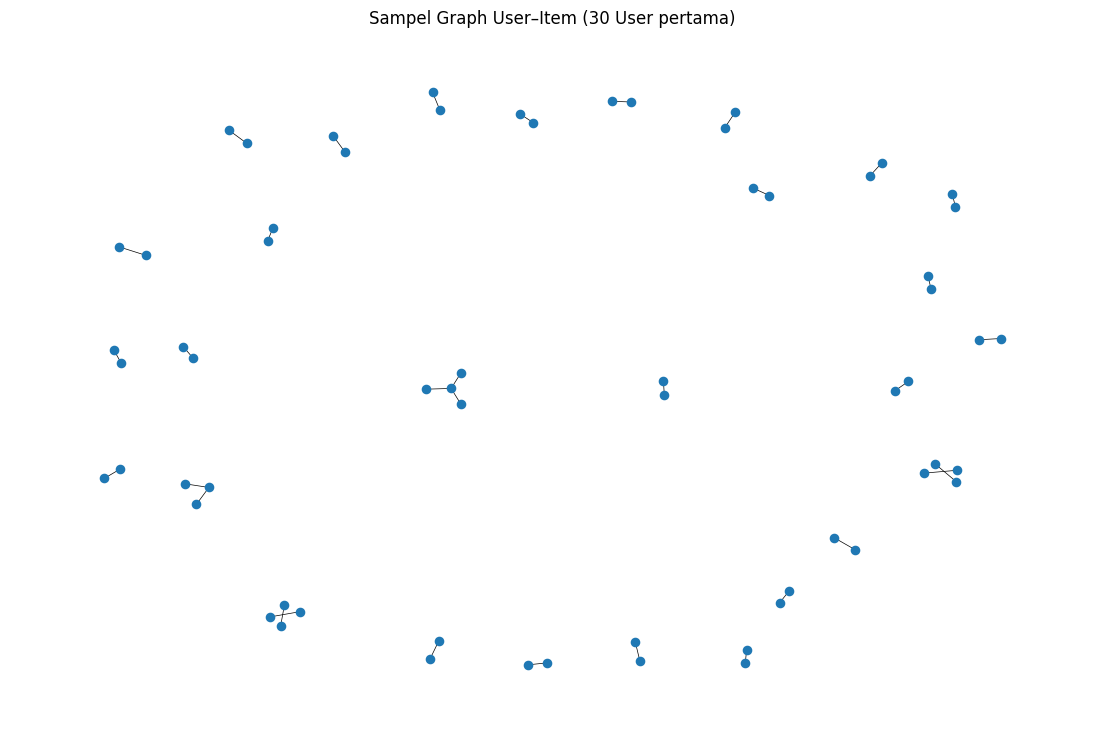

Jumlah node pada plot: 63
Jumlah edge pada plot: 33


In [ ]:
# Ambil sampel 30 User pertama dan item yang berinteraksi dengannya
sample_users = user_ids[:30]
df_sample = df_interaksi[
    df_interaksi["visitorid"].isin(sample_users)
]

G_user = nx.Graph()

for row in df_sample.itertuples(index=False):
    G_user.add_edge(
        f"U{row.visitorid}",
        f"I{row.itemid}",
        weight=row.bobot
    )

plt.figure(figsize=(14, 9))
pos = nx.spring_layout(G_user, seed=42)

nx.draw_networkx(
    G_user,
    pos,
    with_labels=False,
    node_size=35,
    width=0.5
)

plt.title("Sampel Graph User–Item (30 User pertama)")
plt.axis("off")
plt.show()

print("Jumlah node pada plot:", G_user.number_of_nodes())
print("Jumlah edge pada plot:", G_user.number_of_edges())

Berdasarkan visualisasi sampel graph User–Item dari 30 user pertama, terlihat beberapa kelompok node yang terpisah satu sama lain. Node merepresentasikan user dan item, sedangkan edge menunjukkan adanya interaksi antara keduanya. Kelompok yang terpisah menunjukkan bahwa tidak terdapat hubungan interaksi langsung antar-node di kelompok tersebut dengan node pada kelompok lain dalam sampel yang divisualisasikan. Hal ini menggambarkan bahwa interaksi user–item tersebar dalam beberapa kelompok, dan setiap user hanya berinteraksi dengan item tertentu. Visualisasi ini merupakan sampel data sehingga belum menggambarkan keseluruhan struktur graph RetailRocket.

### Nomor 5 — VSM Item

1. VSM pada Simpul Item

In [ ]:
# Matriks Item-User: baris = Item, kolom = User
rows_item = df_user_item["itemid"].map(item_index).to_numpy()
cols_user = df_user_item["visitorid"].map(user_index).to_numpy()
values = df_user_item["bobot"].to_numpy(dtype=float)

X_item = csr_matrix(
    (values, (rows_item, cols_user)),
    shape=(len(item_ids), len(user_ids))
)

print("Jumlah Item:", len(item_ids))
print("Jumlah User:", len(user_ids))
print("Shape matriks VSM Item:", X_item.shape)
print("Jumlah pasangan Item-User unik:", X_item.nnz)


Jumlah Item: 78171
Jumlah User: 155916
Shape matriks VSM Item: (78171, 155916)
Jumlah pasangan Item-User unik: 231267


Matriks VSM Item memiliki ukuran `(78171, 155916)`, yang terdiri atas 78.171 item sebagai baris dan 155.916 user sebagai kolom. Terdapat 231.267 pasangan Item–User yang memiliki nilai interaksi. Setiap baris merepresentasikan pola interaksi suatu item terhadap user. Matriks ini digunakan sebagai dasar untuk menghitung kemiripan antar-item berdasarkan pola interaksi pengunjung.

2. Visualisasi NetworkX untuk VSM Item

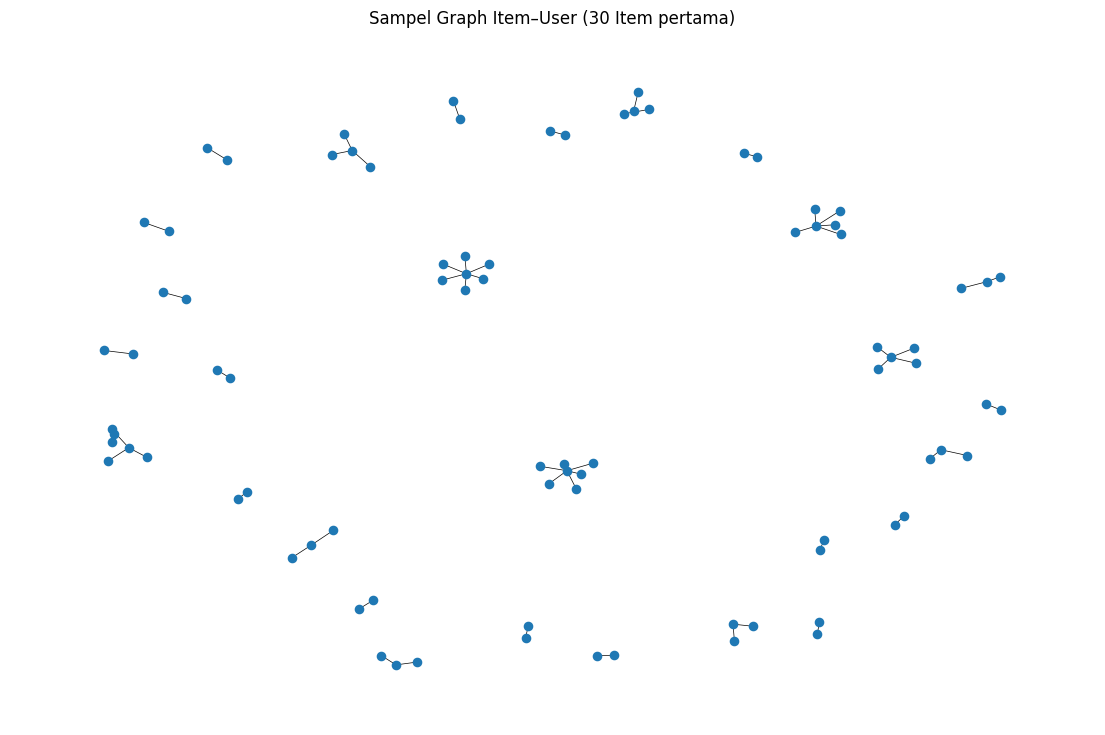

Jumlah Item sampel: 30
Jumlah node pada plot: 86
Jumlah edge pada plot: 56


In [ ]:
# Ambil 30 Item pertama
sample_items = item_ids[:30]

# Gunakan pasangan User-Item yang sudah diagregasi
df_sample_item = df_user_item[
    df_user_item["itemid"].isin(sample_items)
]

G_item = nx.Graph()

for row in df_sample_item.itertuples(index=False):
    G_item.add_edge(
        f"I{row.itemid}",
        f"U{row.visitorid}",
        weight=row.bobot
    )

plt.figure(figsize=(14, 9))
pos_item = nx.spring_layout(G_item, seed=42)

nx.draw_networkx(
    G_item,
    pos_item,
    with_labels=False,
    node_size=35,
    width=0.5
)

plt.title("Sampel Graph Item–User (30 Item pertama)")
plt.axis("off")
plt.show()

print("Jumlah Item sampel:", df_sample_item["itemid"].nunique())
print("Jumlah node pada plot:", G_item.number_of_nodes())
print("Jumlah edge pada plot:", G_item.number_of_edges())

Visualisasi menggunakan 30 item pertama beserta user yang berinteraksi dengannya. Berdasarkan hasil yang diperoleh, terdapat 30 item sampel, 86 node, dan 56 edge. Node merepresentasikan item dan user, sedangkan edge menunjukkan interaksi di antara keduanya.

Kelompok node yang terpisah menunjukkan bahwa tidak terdapat hubungan langsung antara kelompok tersebut dalam sampel. Kondisi ini menggambarkan bahwa pola interaksi user terhadap item berbeda-beda dan tidak semua item terhubung melalui user yang sama. Dalam sistem rekomendasi, pola interaksi ini dapat digunakan sebagai dasar untuk menganalisis kemiripan antar-item menggunakan cosine similarity.

### Nomor 6 — Perbandingan Proyeksi pada VSM User dan VSM Item

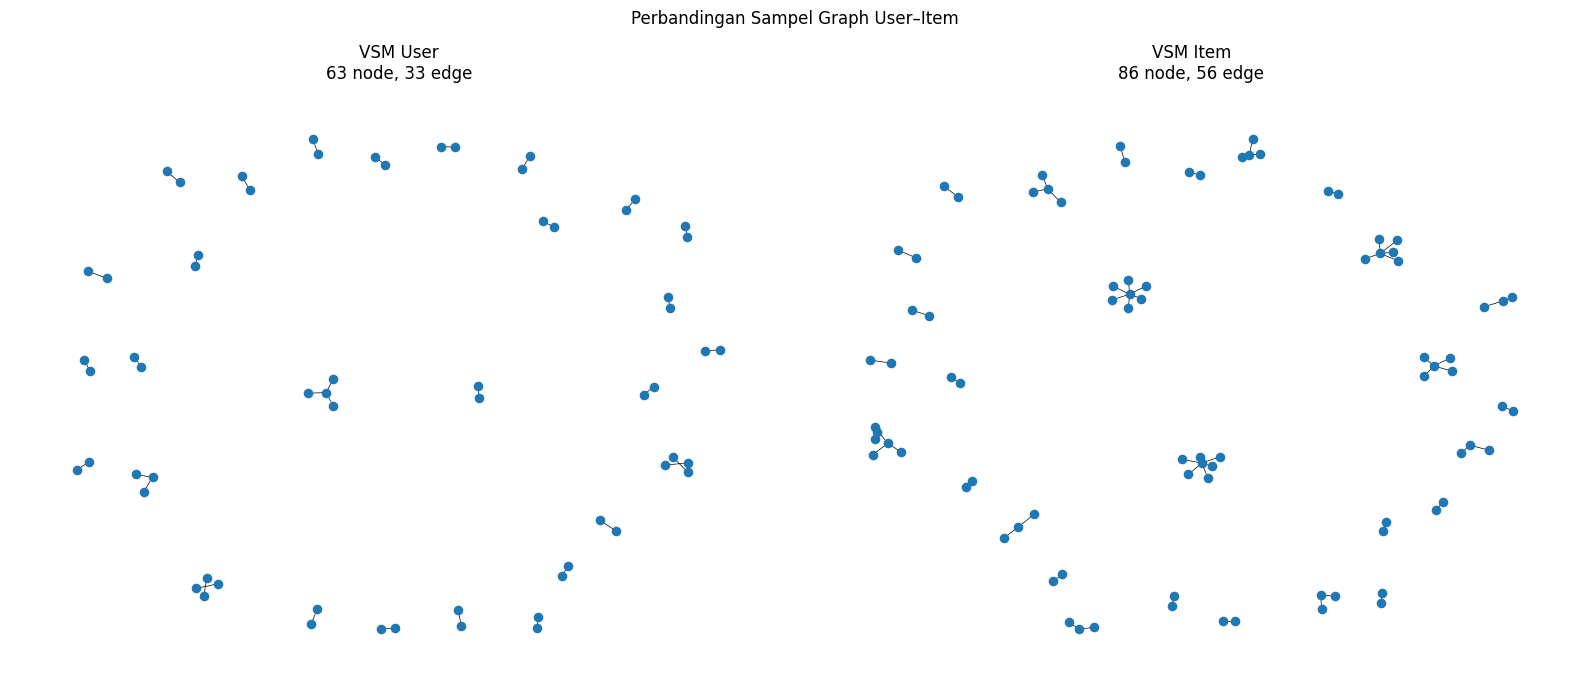

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Panel kiri: sampel graph User–Item dari 30 User pertama
pos_user = nx.spring_layout(G_user, seed=42)
nx.draw_networkx(
    G_user,
    pos=pos_user,
    ax=axes[0],
    with_labels=False,
    node_size=35,
    width=0.5
)
axes[0].set_title(
    f"VSM User\n{G_user.number_of_nodes()} node, "
    f"{G_user.number_of_edges()} edge"
)
axes[0].axis("off")

# Panel kanan: sampel graph Item–User dari 30 Item pertama
pos_item = nx.spring_layout(G_item, seed=42)
nx.draw_networkx(
    G_item,
    pos=pos_item,
    ax=axes[1],
    with_labels=False,
    node_size=35,
    width=0.5
)
axes[1].set_title(
    f"VSM Item\n{G_item.number_of_nodes()} node, "
    f"{G_item.number_of_edges()} edge"
)
axes[1].axis("off")

plt.suptitle("Perbandingan Sampel Graph User–Item")
plt.tight_layout()
plt.show()


Visualisasi VSM User menghasilkan 63 node dan 33 edge dari sampel 30 User pertama, sedangkan VSM Item menghasilkan 86 node dan 56 edge dari sampel 30 Item pertama. Perbedaan jumlah node dan edge menunjukkan bahwa pola interaksi pada kedua sampel berbeda. VSM Item memiliki lebih banyak node dan hubungan pada visualisasi sampel, tetapi hal ini tidak berarti bahwa VSM Item lebih baik secara keseluruhan.

Kedua matriks memiliki 231.267 nilai non-zero dan sparsity sebesar 99,998103%, yang berarti hanya sebagian kecil pasangan User–Item memiliki interaksi. VSM User memiliki shape (155916, 78171) dan sesuai untuk menganalisis kemiripan antar-pengunjung, sedangkan VSM Item memiliki shape (78171, 155916) dan sesuai untuk menganalisis kemiripan antar-item berdasarkan pola pengunjung yang berinteraksi. Pemilihan proyeksi selanjutnya perlu mempertimbangkan tujuan rekomendasi serta efisiensi perhitungan similarity.

### Nomor 7 — Perhitungan similarity dengan Python

Perhitungan Similarity Antar-Item

In [ ]:
X_item_norm = X_item.multiply(
    1 / np.maximum(
        np.sqrt(X_item.multiply(X_item).sum(axis=1).A1),
        1e-12
    )[:, None]
).tocsr()

# Menentukan satu item acuan yang benar-benar ada dalam data
item_acuan = item_ids[0]
idx_acuan = item_index[item_acuan]

# Hitung similarity item acuan dengan seluruh item
similarity = (X_item_norm @ X_item_norm[idx_acuan].T).toarray().ravel()

# Ambil 5 item paling mirip, kecuali item acuan sendiri
similarity[idx_acuan] = -1
top_idx = np.argsort(similarity)[::-1][:5]

df_top_similarity = pd.DataFrame({
    "item_acuan": item_acuan,
    "item_mirip": [item_ids[i] for i in top_idx],
    "similarity": [similarity[i] for i in top_idx]
})

df_top_similarity

,item_acuan,item_mirip,similarity
0,6,453043,1.000000
1,6,318406,0.707107
2,6,174778,0.218218
3,6,466861,0.000000
4,6,466849,0.000000


Perhitungan *cosine similarity* dilakukan dengan menggunakan item acuan **item 6** untuk mencari lima item yang memiliki pola interaksi paling mirip. Berdasarkan hasil perhitungan, item 453043 memperoleh nilai similarity sebesar **1,000**, item 318406 sebesar **0,707**, dan item 174778 sebesar **0,218**. Sementara itu, item 466861 dan 466849 memperoleh nilai **0,000**.

Nilai similarity yang mendekati 1 menunjukkan kemiripan pola interaksi yang tinggi, sedangkan nilai mendekati 0 menunjukkan tidak adanya kemiripan berdasarkan representasi vektor yang digunakan. Hasil ini menunjukkan bahwa setiap item memiliki tingkat kemiripan yang berbeda terhadap item acuan dan dapat digunakan sebagai dasar rekomendasi item serupa.

### nomor 7(a) — Cypher untuk lima similarity tertinggi

1. Menyimpan Similarity ke Neo4j

In [32]:
with driver.session(database="retailrocket") as session:
    rows = df_top_similarity.to_dict(orient="records")

    session.run("""
        UNWIND $rows AS row
        MATCH (a:Item {itemid: row.item_acuan})
        MATCH (b:Item {itemid: row.item_mirip})
        MERGE (a)-[r:SIMILAR_TO]->(b)
        SET r.similarity = row.similarity
    """, rows=rows).consume()

print("Similarity berhasil disimpan ke Neo4j.")

Similarity berhasil disimpan ke Neo4j.


2. Periksa hasilnya dengan Cypher

In [33]:
with driver.session(database="retailrocket") as session:
    result = session.run("""
        MATCH (a:Item {itemid: $item_acuan})-[r:SIMILAR_TO]->(b:Item)
        RETURN
            a.itemid AS item_acuan,
            b.itemid AS item_mirip,
            r.similarity AS similarity
        ORDER BY similarity DESC
    """, item_acuan=int(item_acuan))

    df_similarity_neo4j = pd.DataFrame(
        [dict(record) for record in result]
    )

display(df_similarity_neo4j)


,item_acuan,item_mirip,similarity
0,6,453043,1.000000
1,6,318406,0.707107
2,6,174778,0.218218
3,6,466849,0.000000
4,6,466861,0.000000


3. Visualisasi Graph Sebelum dan Sesudah Similarity

In [34]:
with driver.session(database="retailrocket") as session:
    result = session.run("""
        MATCH ()-[r]->()
        RETURN type(r) AS jenis_relasi, count(r) AS jumlah
        ORDER BY jenis_relasi
    """)
    df_relasi = pd.DataFrame([dict(record) for record in result])

df_relasi

,jenis_relasi,jumlah
0,ADDED_TO_CART,7430
1,BOUGHT,2404
2,SIMILAR_TO,5
3,VIEWED,286485


In [35]:
with driver.session(database="retailrocket") as session:
    result = session.run("""
        MATCH (a:Item)-[r:SIMILAR_TO]->(b:Item)
        RETURN
            a.itemid AS sumber,
            b.itemid AS tujuan,
            r.similarity AS similarity
        ORDER BY r.similarity DESC
    """)

    df_graph_similarity = pd.DataFrame(
        [dict(record) for record in result]
    )

display(df_graph_similarity)

,sumber,tujuan,similarity
0,6,453043,1.000000
1,6,318406,0.707107
2,6,174778,0.218218
3,6,466849,0.000000
4,6,466861,0.000000


4. Visualisasi Graph Setelah Similarity

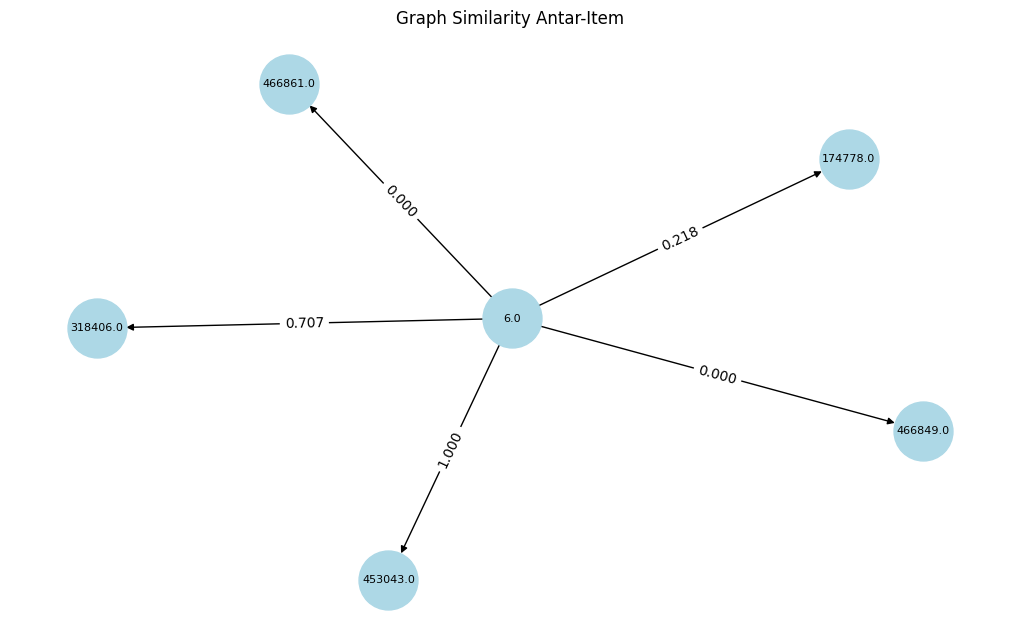

In [123]:
with driver.session(database="retailrocket") as session:
    result = session.run("""
        MATCH (a:Item)-[r:SIMILAR_TO]->(b:Item)
        RETURN a.itemid AS sumber,
               b.itemid AS tujuan,
               r.similarity AS similarity
    """)
    df_graph_similarity = pd.DataFrame(
        [dict(record) for record in result]
    )

G_similarity = nx.DiGraph()

for _, row in df_graph_similarity.iterrows():
    G_similarity.add_edge(
        row["sumber"],
        row["tujuan"],
        similarity=row["similarity"]
    )

pos = nx.spring_layout(G_similarity, seed=42)

plt.figure(figsize=(10, 6))
nx.draw(
    G_similarity,
    pos,
    with_labels=True,
    node_color="lightblue",
    node_size=1800,
    font_size=8,
    arrows=True
)

labels = {
    (u, v): f'{data["similarity"]:.3f}'
    for u, v, data in G_similarity.edges(data=True)
}
nx.draw_networkx_edge_labels(G_similarity, pos, edge_labels=labels)

plt.title("Graph Similarity Antar-Item")
plt.show()

Visualisasi Graph Similarity Antar-Item menunjukkan hubungan kemiripan antara item 6 dan lima item lainnya berdasarkan nilai cosine similarity pada matriks VSM Item. Item 453043 memperoleh nilai tertinggi sebesar 1,000, diikuti item 318406 sebesar 0,707 dan item 174778 sebesar 0,218. Sementara itu, item 466861 dan 466849 memperoleh nilai 0,000. Hasil ini menunjukkan bahwa tingkat kemiripan pola interaksi antar-item berbeda-beda. Nilai similarity kemudian disimpan dalam Neo4j sebagai relasi `SIMILAR_TO` untuk mendukung analisis dan rekomendasi berbasis kemiripan item.

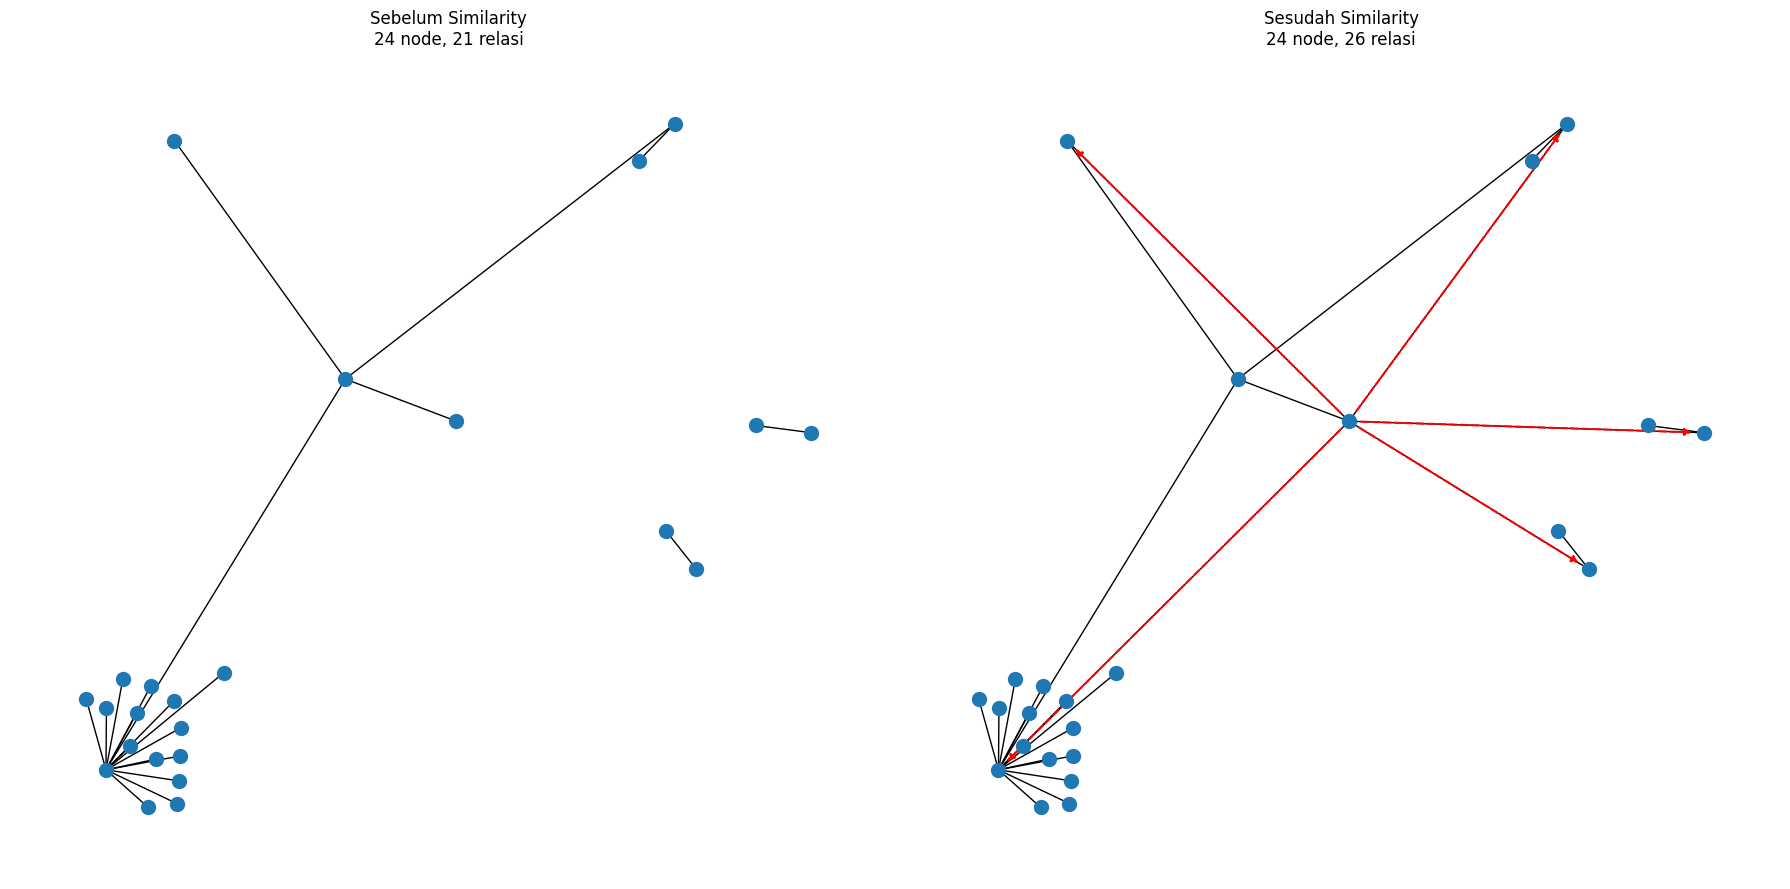

Node sebelum: 24
Relasi sebelum: 21
Node sesudah: 24
Relasi sesudah: 26
Relasi similarity: 5
Node sebelum dan sesudah sama: True


In [125]:
# 1. Ambil item yang terlibat dalam similarity
items_similarity = set(df_graph_similarity["sumber"].dropna())
items_similarity.update(df_graph_similarity["tujuan"].dropna())

# 2. Ambil interaksi asli dari item-item tersebut
df_sample = df_interaksi[
    df_interaksi["itemid"].isin(items_similarity)
].copy()

# Batasi visitor agar grafik mudah dibaca
visitor_sample = sorted(df_sample["visitorid"].unique())[:30]
df_sample = df_sample[
    df_sample["visitorid"].isin(visitor_sample)
]

# 3. Buat graph sebelum similarity
G_before = nx.DiGraph()

for _, row in df_sample.iterrows():
    G_before.add_edge(
        f'V{row["visitorid"]}',
        f'I{row["itemid"]}',
        relation=row["event"]
    )

# Pastikan semua item similarity ada pada graph awal
for item in items_similarity:
    G_before.add_node(f"I{item}")

# 4. Salin graph awal, kemudian tambahkan relasi similarity
G_after = G_before.copy()

for _, row in df_graph_similarity.iterrows():
    sumber = f'I{int(row["sumber"])}'
    tujuan = f'I{int(row["tujuan"])}'

    G_after.add_edge(
        sumber,
        tujuan,
        relation="SIMILAR_TO",
        similarity=float(row["similarity"])
    )

# 5. Validasi jumlah node sebelum visualisasi
assert set(G_before.nodes()) == set(G_after.nodes()), \
    "Node graph sebelum dan sesudah similarity berbeda!"

# 6. Gunakan posisi node yang sama pada kedua grafik
pos = nx.spring_layout(G_after, seed=42)

fig, axes = plt.subplots(1, 2, figsize=(18, 9))

# Grafik sebelum similarity
nx.draw_networkx(
    G_before,
    pos,
    ax=axes[0],
    with_labels=False,
    node_size=100,
    arrows=False
)

axes[0].set_title(
    f"Sebelum Similarity\n"
    f"{G_before.number_of_nodes()} node, "
    f"{G_before.number_of_edges()} relasi"
)
axes[0].axis("off")

# Grafik sesudah similarity
nx.draw_networkx(
    G_after,
    pos,
    ax=axes[1],
    with_labels=False,
    node_size=100,
    arrows=False
)

# Warnai relasi SIMILAR_TO dengan merah putus-putus
similarity_edges = [
    (u, v)
    for u, v, data in G_after.edges(data=True)
    if data.get("relation") == "SIMILAR_TO"
]

nx.draw_networkx_edges(
    G_after,
    pos,
    edgelist=similarity_edges,
    ax=axes[1],
    edge_color="red",
    style="dashed",
    arrows=True,
    width=1.5
)

axes[1].set_title(
    f"Sesudah Similarity\n"
    f"{G_after.number_of_nodes()} node, "
    f"{G_after.number_of_edges()} relasi"
)
axes[1].axis("off")

plt.tight_layout()
plt.show()

# 7. Tampilkan hasil validasi
print("Node sebelum:", G_before.number_of_nodes())
print("Relasi sebelum:", G_before.number_of_edges())
print("Node sesudah:", G_after.number_of_nodes())
print("Relasi sesudah:", G_after.number_of_edges())
print("Relasi similarity:", len(similarity_edges))
print(
    "Node sebelum dan sesudah sama:",
    set(G_before.nodes()) == set(G_after.nodes())
)


# 2.2 Analytics

### Nomor 1 — Rekomendasi Item Menggunakan KNN

1. Menyiapkan data training dan testing

In [152]:
df_train = pd.read_csv("Hasil/events_training.csv")
df_test = pd.read_csv("Hasil/events_testing.csv")

# Bobot interaksi sesuai metode VSM sebelumnya
bobot_event = {
    "view": 1,
    "addtocart": 3,
    "transaction": 5
}

df_train["event"] = (
    df_train["event"].astype(str).str.lower().str.strip()
)
df_test["event"] = (
    df_test["event"].astype(str).str.lower().str.strip()
)

df_train["bobot"] = df_train["event"].map(bobot_event)

# Agregasi bobot setiap pasangan user-item
df_user_item_train = (
    df_train.dropna(subset=["visitorid", "itemid", "bobot"])
    .groupby(["visitorid", "itemid"], as_index=False)
    .agg(bobot=("bobot", "sum"))
)

# ID user dan item dari data training
user_ids = sorted(df_user_item_train["visitorid"].unique())
item_ids = sorted(df_user_item_train["itemid"].unique())

user_index = {u: i for i, u in enumerate(user_ids)}
item_index = {it: i for i, it in enumerate(item_ids)}

# Matriks User-Item
rows = df_user_item_train["visitorid"].map(user_index).to_numpy()
cols = df_user_item_train["itemid"].map(item_index).to_numpy()
values = df_user_item_train["bobot"].to_numpy(dtype=float)

X_train = csr_matrix(
    (values, (rows, cols)),
    shape=(len(user_ids), len(item_ids))
)

# Normalisasi untuk cosine similarity
X_norm = normalize(X_train, norm="l2", axis=1)

print("Shape matriks:", X_train.shape)
print("Jumlah user:", len(user_ids))
print("Jumlah item:", len(item_ids))
print("Jumlah interaksi user-item:", X_train.nnz)

Shape matriks: (155916, 78171)
Jumlah user: 155916
Jumlah item: 78171
Jumlah interaksi user-item: 231267


2: Memilih user secara acak dan reproducible

In [ ]:
SEED = 42
MIN_ITEM_TRAINING = 5

# Mengumpulkan item unik yang pernah diakses setiap user pada training
item_training_user = (
    df_user_item_train.groupby("visitorid")["itemid"]
    .apply(set)
    .to_dict()
)

# Mengumpulkan item unik setiap user pada testing
df_test_user_item = (
    df_test[["visitorid", "itemid"]]
    .dropna()
    .drop_duplicates()
)

item_testing_user = (
    df_test_user_item.groupby("visitorid")["itemid"]
    .apply(set)
    .to_dict()
)

# Menentukan kandidat sebelum melihat hasil rekomendasi
katalog_training = set(item_ids)

user_kandidat = sorted([
    int(uid)
    for uid in item_training_user
    if len(item_training_user[uid]) >= MIN_ITEM_TRAINING
    and uid in item_testing_user
    and len(
        (item_testing_user[uid] - item_training_user[uid])
        & katalog_training
    ) >= 1
])

if not user_kandidat:
    raise ValueError("Tidak ada user yang memenuhi kriteria.")

# Memilih satu user secara acak dengan seed tetap
rng = np.random.default_rng(SEED)
user_acak = int(rng.choice(user_kandidat))

# Item relevan: ada di testing, belum ada di training,
# dan termasuk katalog item training
item_relevan = (
    item_testing_user[user_acak]
    - item_training_user[user_acak]
) & katalog_training

print("Seed:", SEED)
print("Jumlah kandidat:", len(user_kandidat))
print("User terpilih:", user_acak)
print("Jumlah item training:", len(item_training_user[user_acak]))
print("Jumlah item relevan:", len(item_relevan))


Seed: 42
Jumlah kandidat: 620
User terpilih: 123343
Jumlah item training: 16
Jumlah item relevan: 1


3. KNN Recommendation dengan k = 5

In [ ]:
from sklearn.metrics.pairwise import cosine_similarity

K = 5

# Ambil indeks user yang dipilih
idx_user = user_index[user_acak]

# Hitung kemiripan user terpilih dengan semua user
similarities = cosine_similarity(
    X_norm[idx_user],
    X_norm
).ravel()

# User tidak boleh menjadi tetangganya sendiri
similarities[idx_user] = -1

# Ambil 5 tetangga dengan similarity tertinggi
neighbor_indices = np.argsort(similarities)[::-1][:K]

neighbors = [
    (user_ids[i], float(similarities[i]))
    for i in neighbor_indices
    if similarities[i] > 0
]

print("User terpilih:", user_acak)
print("\n5 tetangga terdekat:")
for uid, sim in neighbors:
    print(f"User {uid} | Similarity: {sim:.4f}")

# Hitung skor item berdasarkan bobot interaksi tetangga
scores = np.zeros(len(item_ids), dtype=float)

for uid, sim in neighbors:
    idx_neighbor = user_index[uid]
    scores += sim * X_train[idx_neighbor].toarray().ravel()

# Jangan rekomendasikan item yang sudah ada di training user
items_seen = item_training_user[user_acak]

for item in items_seen:
    if item in item_index:
        scores[item_index[item]] = -1

# Urutkan item berdasarkan skor tertinggi
ranking_indices = np.argsort(scores)[::-1]

recommendations = []
for idx in ranking_indices:
    if scores[idx] < 0:
        continue

    item_id = item_ids[idx]
    recommendations.append({
        "itemid": int(item_id),
        "score": float(scores[idx])
    })

    if len(recommendations) == 5:
        break

df_rekomendasi = pd.DataFrame(recommendations)

print("\nTop-5 rekomendasi:")
display(df_rekomendasi)

print("\n3 item rekomendasi:")
display(df_rekomendasi.head(3))


User terpilih: 123343

5 tetangga terdekat:
User 1311615 | Similarity: 0.6145
User 1333677 | Similarity: 0.3961
User 600764 | Similarity: 0.3961
User 1241916 | Similarity: 0.3961
User 210570 | Similarity: 0.3961

Top-5 rekomendasi:


,itemid,score
0,379650,8.603644
1,381265,3.072730
2,301229,1.229092
3,386382,1.229092
4,92074,1.229092



3 item rekomendasi:


,itemid,score
0,379650,8.603644
1,381265,3.072730
2,301229,1.229092


### Nomor 2 — Berdasarkan hasil rekomendasi Anda no. 1b Analytics, hitunglah: 

4. Evaluasi Hit@5 dan NDCG@5

In [ ]:
K = 5

# Ambil daftar Top-5 hasil rekomendasi
top_k_items = df_rekomendasi.head(K)["itemid"].astype(int).tolist()

# Item relevan dari data testing yang belum muncul di training
relevant_items = set(int(item) for item in item_relevan)

# Relevansi tiap item: 1 jika relevan, 0 jika tidak
relevance = [
    1 if item in relevant_items else 0
    for item in top_k_items
]

# Hit@5: bernilai 1 jika minimal satu item relevan ditemukan
hit_at_5 = int(sum(relevance) > 0)

# DCG@5
dcg_at_5 = sum(
    rel / np.log2(rank + 2)
    for rank, rel in enumerate(relevance)
)

# IDCG@5: DCG ideal berdasarkan jumlah item relevan yang tersedia
ideal_relevance = [1] * min(len(relevant_items), K)

idcg_at_5 = sum(
    rel / np.log2(rank + 2)
    for rank, rel in enumerate(ideal_relevance)
)

# NDCG@5
ndcg_at_5 = dcg_at_5 / idcg_at_5 if idcg_at_5 > 0 else 0.0

print("User ID:", user_acak)
print("Top-5 rekomendasi:", top_k_items)
print("Item relevan:", sorted(relevant_items))
print("Relevansi Top-5:", relevance)
print("Hit@5:", hit_at_5)
print("NDCG@5:", round(ndcg_at_5, 4))


User ID: 123343
Top-5 rekomendasi: [379650, 381265, 301229, 386382, 92074]
Item relevan: [379650]
Relevansi Top-5: [1, 0, 0, 0, 0]
Hit@5: 1
NDCG@5: 1.0


Pengujian dilakukan pada user ID 123343 yang dipilih secara acak menggunakan random seed 42. Sistem rekomendasi menggunakan metode K-Nearest Neighbors (KNN) dengan \(k=5\), berdasarkan cosine similarity antaruser dan bobot interaksi pada data training.

Sistem menghasilkan lima rekomendasi teratas, yaitu item ID 379650, 381265, 301229, 386382, dan 92074. Dari lima item tersebut, terdapat satu item relevan berdasarkan data testing, yaitu item ID 379650, yang menempati peringkat pertama.

Hasil evaluasi memperoleh nilai **Hit@5 sebesar 1** dan **NDCG@5 sebesar 1,0**. Hit@5 sebesar 1 menunjukkan bahwa setidaknya satu item relevan berhasil ditemukan dalam lima rekomendasi teratas. NDCG@5 sebesar 1,0 menunjukkan bahwa item relevan yang ditemukan berada pada posisi paling optimal, yaitu peringkat pertama.

Dengan demikian, sistem berhasil merekomendasikan satu item relevan untuk user yang diuji. Namun, hasil ini hanya menggambarkan performa pada satu user dan belum dapat mewakili kinerja sistem untuk seluruh pengguna.